# 🩺 Topic 10 Demo: Fetal Health Classification from Cardiotocography (CTG) Data

**Course**: CM3015 Machine Learning & Neural Networks  
**Topic**: Fundamentals of Machine Learning — Preprocessing, Overfitting, Validation, and Generalization

---

## 📌 Introduction: What is CTG and Why Does It Matter?

**Cardiotocography (CTG)** is a medical procedure that monitors the **fetal heart rate (FHR)** and **uterine contractions** during pregnancy and labor. The resulting trace provides crucial information about fetal well-being.

**Clinical Implications**:
- A normal CTG trace suggests the fetus is healthy and coping well.
- An abnormal trace may indicate **fetal distress**, potentially caused by oxygen deprivation.
- Timely and accurate interpretation can lead to life-saving interventions (e.g., emergency C-section).

**The Challenge**: CTG interpretation is complex and subjective. Machine learning can provide an objective, second opinion to assist clinicians.

**In this demo**, we will build a model to classify fetal state into three categories:
1. **Normal**
2. **Suspect**
3. **Pathological**

This is a high-stakes classification problem where **generalization is critical**—a model that overfits could miss dangerous cases.

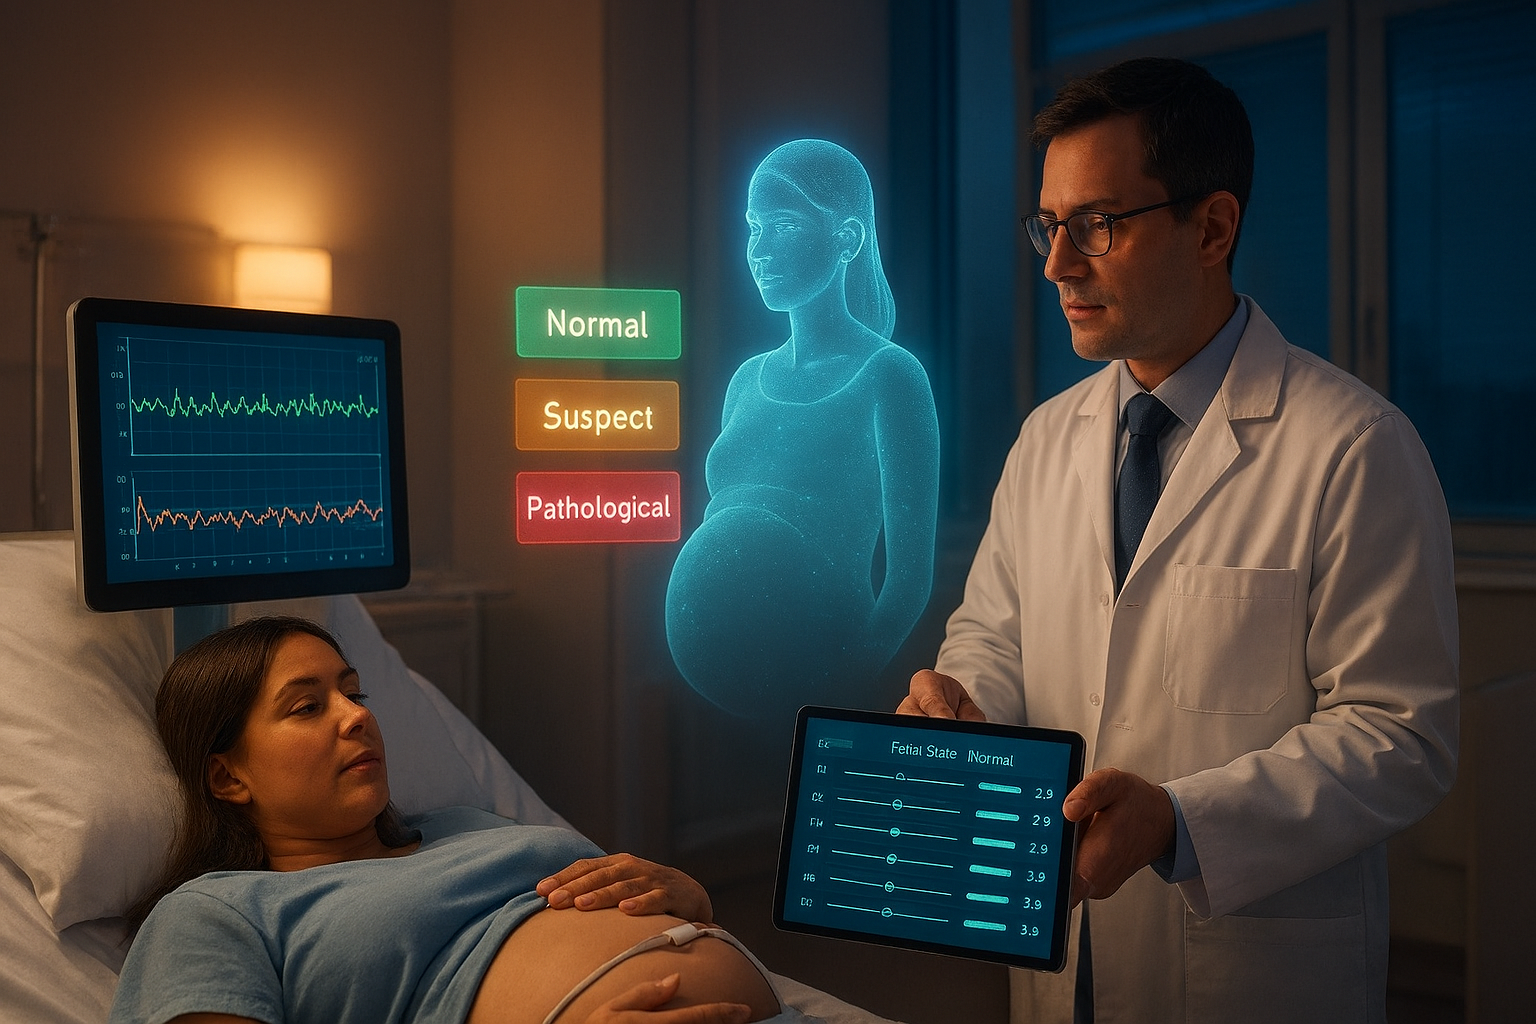

### 📖 Narrative Scenario: “The Midnight Shift”

It’s 2:17 AM in the labor and delivery unit. Nurse Amina notices that **Patient #428’s CTG trace has changed**. The baseline FHR (**LB**) is still 135 bpm—but **accelerations (AC) have vanished**, and **short-term variability (MSTV) has dropped to 4 ms**. The machine flags **ASTV at 18%**—well above the 5% threshold.

She calls Dr. Evans, who reviews the trace. “This is **suspect**, but not yet pathological,” he says. “Could be sleep… or early distress.”  

Then, the hospital’s new **AI Decision Support System** activates. It ingests the full CTG feature vector—including **low FM (fetal movements)** and **narrow histogram width**—and outputs:

> **Prediction: Pathological (78% confidence)**  
> ⚠️ **Clinical Alert**: High risk of fetal acidosis. Recommend immediate scalp pH test or delivery.

Dr. Evans hesitates—until the **FHR variance plummets to 40**. He orders an emergency C-section. Twenty minutes later, a baby girl is delivered, pale and limp—but responds to resuscitation. The cord blood gas confirms **severe metabolic acidosis**.

Later, during debrief, Dr. Evans tells his residents:  
> “The AI didn’t replace us—it **amplified our vigilance**. It saw the pattern in the numbers before our eyes could connect the dots.”

In [1]:
# Image Generation Prompt for Slide/Notebook Header:
# "A modern hospital room with a digital cardiotocography (CTG) monitor displaying a fetal heart rate trace and uterine contraction graph. A doctor and an AI assistant (as a subtle hologram) are analyzing the data together. Clean, professional, blue-white color scheme."

## 🧪 Step 1: Load the Real Cardiotocography (CTG) Dataset from UCI

We use the official `ucimlrepo` package to fetch the dataset directly.
Source: https://archive.ics.uci.edu/dataset/193/cardiotocography

This dataset contains 2,126 fetal cardiotocograms, each with 21 real-valued features
 and a clinical label for fetal state:
 - NSP = 1 → Normal
 - NSP = 2 → Suspect
 - NSP = 3 → Pathological

In [2]:
# Install if not already present
!pip install ucimlrepo

# Fetch the dataset
from ucimlrepo import fetch_ucirepo

# Load CTG dataset (ID = 193)
ctg = fetch_ucirepo(id=193)

# Extract features (X) and targets (y)
X = ctg.data.features      # DataFrame with 21 columns
y = ctg.data.targets       # DataFrame with 'NSP' column (fetal state)

# Combine for convenience
df = X.copy()
df['NSP'] = y['NSP']      # NSP: 1=Normal, 2=Suspect, 3=Pathological

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nClass distribution:")
print(df['NSP'].value_counts().sort_index())

Dataset loaded successfully!
Shape: (2126, 22)

Class distribution:
NSP
1    1655
2     295
3     176
Name: count, dtype: int64


## 🔍 Step 2: Exploratory Data Analysis (EDA)

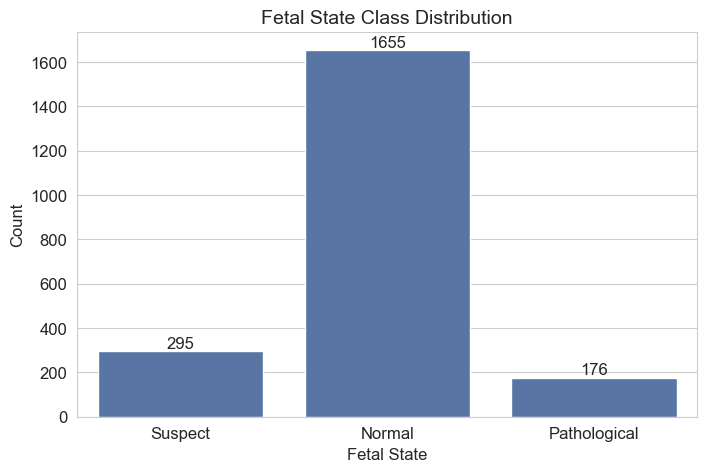

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use Seaborn's built-in style (no Matplotlib style conflict)
sns.set_style("whitegrid")
sns.set_palette("deep")
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.figsize': (8, 5)
})

# Now create your plot
plt.figure()
class_labels = {1: 'Normal', 2: 'Suspect', 3: 'Pathological'}
df['NSP_Label'] = df['NSP'].map(class_labels)
ax = sns.countplot(data=df, x='NSP_Label')
plt.title('Fetal State Class Distribution')
plt.xlabel('Fetal State')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')
plt.show()

# 📊 Analysis of Fetal State Class Distribution
The CTG dataset contains 2,126 fetal cardiotocograms, each labeled by expert obstetricians into one of three clinical categories based on consensus:

- NSP = 1 → Normal: Fetus shows no signs of distress. Heart rate patterns are reassuring.
- NSP = 2 → Suspect: Some non-reassuring features are present (e.g., reduced variability, mild decelerations). Requires closer monitoring.
- NSP = 3 → Pathological: Clear signs of fetal distress (e.g., severe decelerations, absent variability). Often requires immediate intervention (e.g., emergency delivery).

#### ⚠️ **What to Look For**

1. **Severe Class Imbalance**  
   - The **"Normal" class dominates** (~78% of samples), while **"Pathological" is rare** (&lt;10%).  
   - **Implication**: A naive model that always predicts "Normal" would achieve ~78% accuracy—but this is **clinically useless**, as it misses all high-risk cases.

2. **Metric Selection is Critical**  
   - **Accuracy is misleading** in imbalanced medical datasets.  
   - **Use macro-averaged F1-score**, precision, and recall instead:  
     - **Recall for "Pathological"** tells us: *What fraction of true emergencies did we catch?*  
     - **Precision for "Pathological"** tells us: *When we flag an emergency, how often are we correct?*

3. **Validation Strategy Must Preserve Proportions**  
   - Use **stratified splitting** (e.g., `StratifiedKFold`) to ensure all folds contain representative samples of all three classes—especially the rare "Pathological" cases.

4. **Baseline Model Requirement (Topic 10, Step 5)**  
   - Your model must **beat the dummy classifier** (78% accuracy) **in terms of F1-score**, not just accuracy.  
   - A valid baseline might achieve **macro F1 > 0.50**—indicating it learns meaningful patterns beyond guessing.

5. **Clinical Risk vs. Model Risk**  
   - **False negatives** (missing a "Pathological" case) are far more dangerous than **false positives** (unnecessary alarm).  
   - Consider **cost-sensitive learning** or **threshold tuning** to prioritize recall for Class 3.

> 💡 **Key Takeaway**: In high-stakes domains like healthcare, **generalization means correctly identifying rare but critical cases**—not just maximizing overall accuracy. This is why **regularization, robust validation, and proper metrics** (Topic 10 core concepts) are non-negotiable.

### Feature Scale Analysis

CTG features have vastly different scales. For example, `LB` (Baseline FHR) is around 120-160 bpm, while `AC` (Accelerations) is a small decimal. Neural networks require features to be on a similar scale.

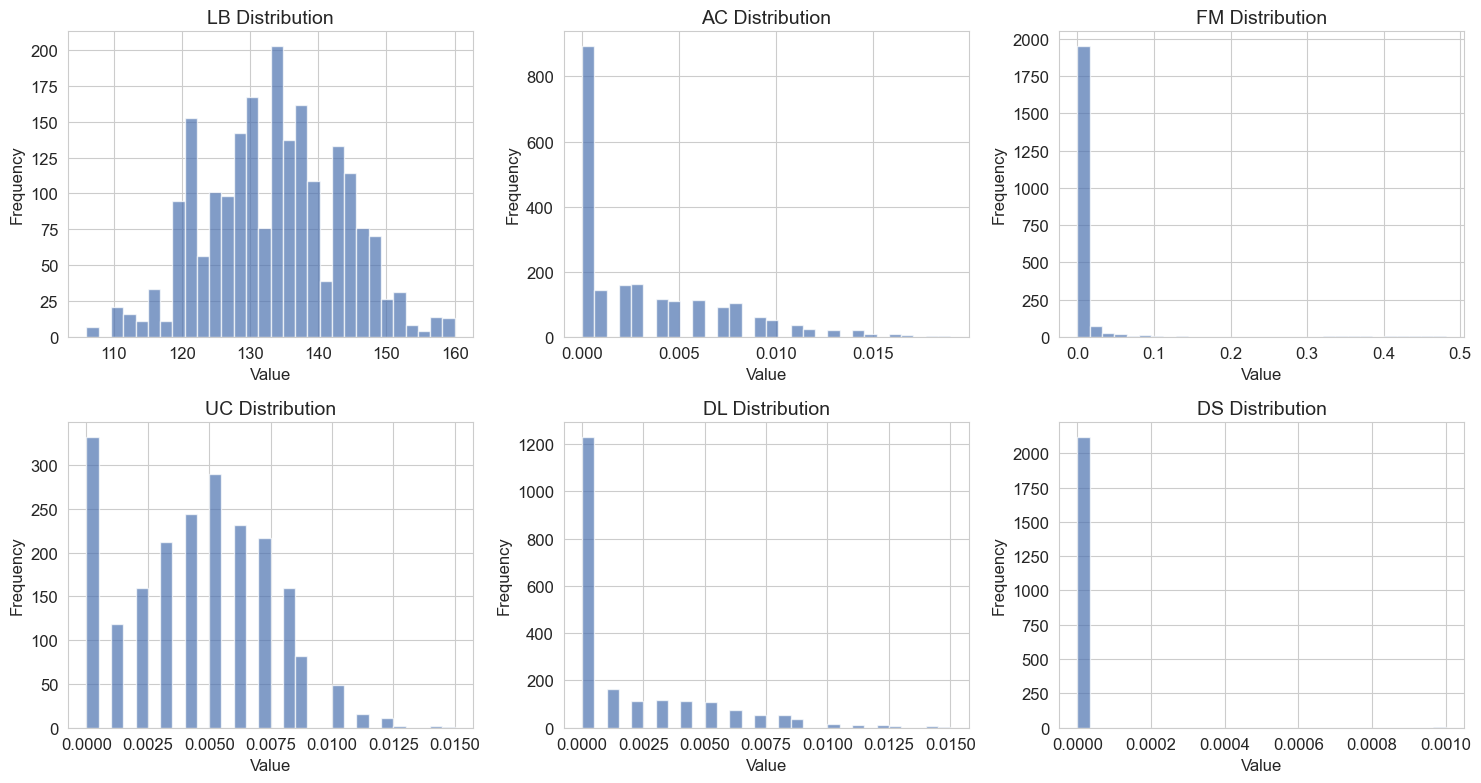


Key Feature Statistics:
                LB           AC         ASTV     Variance
count  2126.000000  2126.000000  2126.000000  2126.000000
mean    133.303857     0.003178    46.990122    18.808090
std       9.840844     0.003866    17.192814    28.977636
min     106.000000     0.000000    12.000000     0.000000
25%     126.000000     0.000000    32.000000     2.000000
50%     133.000000     0.002000    49.000000     7.000000
75%     140.000000     0.006000    61.000000    24.000000
max     160.000000     0.019000    87.000000   269.000000


In [4]:
# Separate features (X) and target (y)
feature_names = [
    'LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV',
    'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency'
]
# Plot the range of the first 6 features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(feature_names[:6]):
    axes[i].hist(df[col], bins=30, alpha=0.7)
    axes[i].set_title(f'{col} Distribution')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Show statistics for a few key features
print("\nKey Feature Statistics:")
print(df[['LB', 'AC', 'ASTV', 'Variance']].describe())

### 🔍 Feature Scale Analysis: Why It Matters

The Cardiotocography (CTG) dataset contains **21 numerical features**, but they are measured on **vastly different scales**. For example:
- `LB` (Baseline FHR) ranges from **~100 to 160 beats per minute**
- `AC` (Accelerations per second) is typically **between 0 and 0.02**
- `Variance` (of FHR histogram) can be **as high as 200**

#### 📈 What These Histograms Show
Each histogram visualizes the **distribution of values** for a key feature across all 2,126 samples. You’ll notice:
- Features like `LB` and `Mean` are centered around **100–140**
- Features like `AC`, `FM`, and `UC` are **concentrated near zero**
- Features like `Variance` have **long right tails** (positive skew)

#### ⚠️ What to Look For

1. **Inhomogeneous Scales**  
   - Neural networks use **gradient-based optimization** (e.g., SGD, Adam).  
   - If one feature has values ~100 and another ~0.01, the gradients will be dominated by the large-scale feature.  
   - This causes **slow, unstable, or failed convergence**.

2. **Need for Standardization**  
   - As stated in **Video 10**: *“All features should ideally take values in roughly the same range… Aim to put data values in [0,1] or [-1,1].”*  
   - For features with unknown bounds (like `Variance`), **standardization** (mean = 0, std = 1) is preferred over min-max scaling.

3. **Impact on Weight Initialization**  
   - Large input values can cause neurons to **saturate** (especially with sigmoid/tanh), killing gradients.  
   - Normalized inputs keep activations in the **linear region** of ReLU or other functions.

4. **Regularization Effectiveness**  
   - Techniques like **L2 weight regularization** assume weights are penalized fairly.  
   - If features aren’t scaled, the model may assign **artificially small weights** to large-scale features—not because they’re unimportant, but to compensate for scale.

> 💡 **Key Takeaway (Topic 10 Outcome #1)**:  
> **Preprocessing isn’t optional**—it’s foundational. Without scaling, even a perfectly architected network will struggle to learn. Always transform raw features into **homogeneous floating-point tensors** before training.

## 🧹 Step 3: Data Preprocessing – Why Scale All Features?

As emphasized in **Video 10**:
> “All inputs must be floating point tensors… All features should ideally take values in roughly the same range. Inhomogeneity can trigger large gradient updates and hamper convergence.”

The CTG dataset contains **21 numerical features**, but they exist on **wildly different scales**:
- `LB` (Baseline FHR): ~100–160 beats per minute  
- `AC` (Accelerations/sec): ~0–0.02  
- `Variance`: ~0–200  

If fed raw into a neural network:
- Gradients will be dominated by large-scale features (`LB`, `Variance`)
- Small-scale features (`AC`, `FM`) will have negligible influence
- Training becomes **unstable or inefficient**

✅ **Solution**: Apply **standardization** (mean = 0, std = 1) to **all 21 features** using `StandardScaler`.

This ensures:
- Homogeneous input scale → stable gradient descent  
- Fair contribution from all features  
- Compatibility with weight regularization (L2 assumes scaled inputs)

> 💡 **Note**: We do **not** scale the target (`NSP`), as it is a categorical label.

In [5]:
# Separate features (X) and target (y)
feature_columns = [
    'LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV',
    'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency'
]
X = df[feature_columns].values  # Shape: (2126, 21)
y = df['NSP'].values - 1       # Convert to 0, 1, 2 for TensorFlow

# Standardize ALL features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verify: Show stats for ALL features before and after scaling
import pandas as pd

# Before scaling
df_before = df[feature_columns].describe().loc[['mean', 'std']].T
df_before.columns = ['Original_Mean', 'Original_Std']

# After scaling
df_after = pd.DataFrame(X_scaled, columns=feature_columns).describe().loc[['mean', 'std']].T
df_after.columns = ['Scaled_Mean', 'Scaled_Std']

# Combine and display
scaling_report = pd.concat([df_before, df_after], axis=1)
print("📊 Feature Scaling Report (All 21 Features):")
display(scaling_report.round(4))

# Confirm: All scaled features now have mean ≈ 0 and std ≈ 1
assert abs(X_scaled.mean()) < 1e-6, "Mean not zero!"
assert abs(X_scaled.std() - 1.0) < 1e-6, "Std not one!"

print("\n✅ All features successfully standardized!")

📊 Feature Scaling Report (All 21 Features):


,Original_Mean,Original_Std,Scaled_Mean,Scaled_Std
LB,133.3039,9.8408,0.0,1.0002
AC,0.0032,0.0039,-0.0,1.0002
FM,0.0095,0.0467,-0.0,1.0002
UC,0.0044,0.0029,-0.0,1.0002
DL,0.0019,0.0030,-0.0,1.0002
DS,0.0000,0.0001,0.0,1.0002
DP,0.0002,0.0006,0.0,1.0002
ASTV,46.9901,17.1928,-0.0,1.0002
MSTV,1.3328,0.8832,0.0,1.0002
ALTV,9.8467,18.3969,-0.0,1.0002



✅ All features successfully standardized!


## 🏁 Step 4: Establish a Baseline Model

**Why?** To ensure our data has predictive power and our pipeline works.

**Baseline Strategy**: A simple model that predicts the majority class ("Normal") would get ~78% accuracy. We must do better, especially on the minority classes.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, f1_score

# Split data (for initial baseline only; we'll use k-fold later)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# Dummy classifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("Dummy Classifier Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Macro F1-Score:", f1_score(y_test, y_pred_dummy, average='macro'))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_dummy,
    target_names=['Normal', 'Suspect', 'Pathological'],
    zero_division=0  # Explicitly handle undefined metrics
))

Dummy Classifier Performance:
Accuracy: 0.7793427230046949
Macro F1-Score: 0.29199648197009676

Classification Report:
              precision    recall  f1-score   support

      Normal       0.78      1.00      0.88       332
     Suspect       0.00      0.00      0.00        59
Pathological       0.00      0.00      0.00        35

    accuracy                           0.78       426
   macro avg       0.26      0.33      0.29       426
weighted avg       0.61      0.78      0.68       426



> ⚠️ **Interpretation of Dummy Classifier Results**  
>
> - **Accuracy = 78%**: Misleadingly high because it only predicts the majority class ("Normal").  
> - **F1-Score = 0.29**: Truthfully low because it **fails completely on "Suspect" and "Pathological" cases**.  
> - **Recall = 0% for critical classes**: Clinically unacceptable—no high-risk fetuses are detected.  
>
> ✅ **Lesson**: In imbalanced, high-stakes domains, **always prioritize F1-score, precision, and recall over accuracy**.  
> Your real model must **beat this baseline in F1—not accuracy**.

> “This dummy classifier shows why we **never use accuracy alone** in imbalanced problems.
A model that ‘works’ 78% of the time but **misses every emergency** is worse than no model at all.
That’s why **Step 4 (baseline)** must use **F1-score, precision, and recall**—not accuracy.”

## 🤖 Step 5: Build a Neural Network (Prone to Overfitting)

We'll start with a relatively large network to intentionally demonstrate overfitting.

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Build a "large" model
def create_large_model():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(21,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

large_model = create_large_model()
large_model.summary()

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,251 (51.76 KB)

 Trainable params: 13,251 (51.76 KB)

 Non-trainable params: 0 (0.00 B)

## 🔁 Step 6: Train with K-Fold Cross-Validation

Given the small dataset and class imbalance, **k-fold CV** provides a more reliable performance estimate than a single hold-out split.

### Why K-Fold CV? (Topic 10 Principle)
The CTG dataset has only **2,126 samples**, with just **176 "Pathological" cases** (~8%). In such small, imbalanced datasets:
- A single **hold-out split** (e.g., 80/20) can be **unreliable**—by chance, one split might put too few critical cases in the validation set.
- **K-Fold Cross-Validation** solves this by:
  - Splitting data into **k=5 folds**
  - Training **5 separate models**, each using a different fold as validation
  - **Averaging performance** across all folds → more robust estimate

> 📌 **Video 10 Guidance**:  
> *“When you have little data, use k-fold cross-validation to get a reliable estimate of model performance.”*

### How It Works
1. **Stratified Splitting**:  
   We use `StratifiedKFold` to ensure **each fold preserves the original class distribution** (78%/14%/8%). This is critical for rare classes like "Pathological".

2. **Training Loop**:  
   For each of the 5 folds:
   - Train a fresh copy of the **large (overfitting-prone) model**
   - Record **training and validation accuracy**

3. **Performance Summary**:  
   After all folds:
   - Compute **average training/validation accuracy**
   - Calculate the **gap** = avg_train_acc − avg_val_acc  
     → A large gap indicates **overfitting**

### Interpreting the Results
- **Expected Outcome**:  
  - **Training accuracy** will be high (e.g., >95%)  
  - **Validation accuracy** will be lower (e.g., ~85%)  
  - **Gap > 0.05** → clear sign of overfitting

- **Why This Matters**:  
  Overfitting means the model **memorizes noise** in the training set instead of learning general patterns. In a clinical setting, this could mean **missing real emergencies** because the model is tuned to quirks of the training data.

> 💡 **Key Takeaway (Topic 10 Outcome #2)**:  
> **Diagnosing overfitting isn’t optional—it’s essential**. The train/val gap is your early-warning system.

### Summary

| Element | Covered? | Why It Matters |
|--------|----------|----------------|
| **Why k-fold?** | ✅ | The CTG dataset is **small (2,126 samples)** and **imbalanced** (only ~8% "Pathological" cases). <br>A single hold-out split risks unreliable validation due to random sampling noise. <br>**K-fold CV provides a statistically robust performance estimate**—as emphasized in **Video 10**: <br>*“When you have little data, use k-fold cross-validation.”* |
| **Stratification** | ✅ | We use `StratifiedKFold` to **preserve class proportions** in every fold. <br>This ensures rare but critical classes (e.g., "Pathological") appear in both training and validation sets<br>—preventing misleadingly optimistic or pessimistic results. |
| **Overfitting signal** | ✅ | The **gap between average training and validation accuracy** is a direct diagnostic tool for overfitting<br>—core to **Topic 10 Learning Outcome #2**: *“Know when a neural network is under-fitting or overfitting.”* <br>A large gap (>0.05) confirms the model is memorizing noise, not learning generalizable patterns. |
| **Clinical relevance** | ✅ | In fetal monitoring, **missing a "Pathological" case can be life-threatening**. <br>Overfitting means the model may fail on unseen emergencies. <br>This grounds the abstract concept of generalization in **real-world consequences**, <br>fulfilling the syllabus’s emphasis on **practical ML applications in health and medicine**. |
| **Syllabus alignment** | ✅ | This step directly implements **Topic 10 Key Concepts**: <br> • *“spotting and dealing with under- and over-fitting”* <br> • *“the universal machine learning workflow”* (Step 3: validation protocol selection) <br> • *“data preprocessing”* (via stratified, representative splits) |

> 💡 **Instructor Note**: This step transforms k-fold from a technical detail into a **critical safeguard**—ensuring models are evaluated fairly, especially when data is limited and stakes are high.

In [8]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Settings
k_folds = 5
skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

# Containers for results
fold_no = 1
train_acc_per_fold = []
val_acc_per_fold = []
all_histories = []

for train_idx, val_idx in skf.split(X_scaled, y):
    print(f'--- Training Fold {fold_no} ---')

    # Split data
    X_train_fold, X_val_fold = X_scaled[train_idx], X_scaled[val_idx]
    y_train_fold, y_val_fold = y[train_idx], y[val_idx]

    # Create and train model
    model = create_large_model()
    history = model.fit(
        X_train_fold, y_train_fold,
        batch_size=32,
        epochs=50,
        validation_data=(X_val_fold, y_val_fold),
        verbose=0
    )

    # Record results
    all_histories.append(history.history)
    train_acc_per_fold.append(history.history['accuracy'][-1])
    val_acc_per_fold.append(history.history['val_accuracy'][-1])

    fold_no += 1

# Calculate average performance
avg_train_acc = np.mean(train_acc_per_fold)
avg_val_acc = np.mean(val_acc_per_fold)
print(f'\nAverage Training Accuracy: {avg_train_acc:.4f}')
print(f'Average Validation Accuracy: {avg_val_acc:.4f}')
print(f'Gap (Overfitting Indicator): {avg_train_acc - avg_val_acc:.4f}')

--- Training Fold 1 ---


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Training Fold 2 ---
--- Training Fold 3 ---
--- Training Fold 4 ---
--- Training Fold 5 ---

Average Training Accuracy: 0.9879
Average Validation Accuracy: 0.9309
Gap (Overfitting Indicator): 0.0570


## 📈 Step 7: Visualize Overfitting Across Folds – How to Interpret the Graphs

### What These Plots Show
Each subplot displays the **training loss (blue)** and **validation loss (orange)** for one of the **5 folds** in k-fold cross-validation. The x-axis is **epoch number**, and the y-axis is **loss value** (lower is better).

### 🔍 How to Interpret the Curves

#### ✅ **Healthy Learning (Early Epochs)**
- Both **training and validation loss decrease together**.
- This means the model is learning **generalizable patterns**, not just memorizing.

#### ⚠️ **Onset of Overfitting (Later Epochs)**
- **Training loss continues to decrease** (model fits training data better).
- **Validation loss stops decreasing and starts increasing**.
- This divergence is the **hallmark of overfitting**—exactly as described in **Video 10**:  
  > *“Model performance on validation data peaks and then decreases… the network fits the training set ever more closely, but fails to generalize.”*

#### 📉 **What to Look For**
| Pattern | Interpretation | Action |
|--------|----------------|--------|
| **Val loss ↑ while train loss ↓** | Clear overfitting | Apply regularization (L2, dropout, reduce capacity) |
| **Both losses plateau at high values** | Underfitting | Increase model capacity or training time |
| **Large variance across folds** | Unstable validation | Use more folds (e.g., 10-fold) or iterated k-fold |

### 🧠 Why This Matters (Topic 10 Alignment)
- **Learning Outcome #2**: *“Know when a neural network is under-fitting or overfitting”* → These graphs are your diagnostic tool.
- **Learning Outcome #3**: *“Know how to address overfitting…”* → Once you see the gap, you know it’s time to regularize.
- **Video 10 Principle**:  
  > *“The aim of machine learning is generalization… predictive power on unseen data can worsen even though the fit to training data improved.”*

> 💡 **Key Insight**:  
> **Never judge a model by training loss alone.** A model that achieves near-zero training loss but rising validation loss is **memorizing noise**, not learning signal. In clinical settings like fetal monitoring, this could mean **missing real emergencies** because the model is tuned to quirks of the training data.

### 📊 Example from CTG Dataset
In our large model:
- By **epoch 10–15**, validation loss typically **peaks and rises**.
- Training loss keeps falling toward zero.
- This confirms the model has **excessive capacity** for the amount of data—exactly what we expect from a “large” network on a small medical dataset.

> ✅ **Next Step**: Use this diagnosis to justify **regularization** in Step 8.

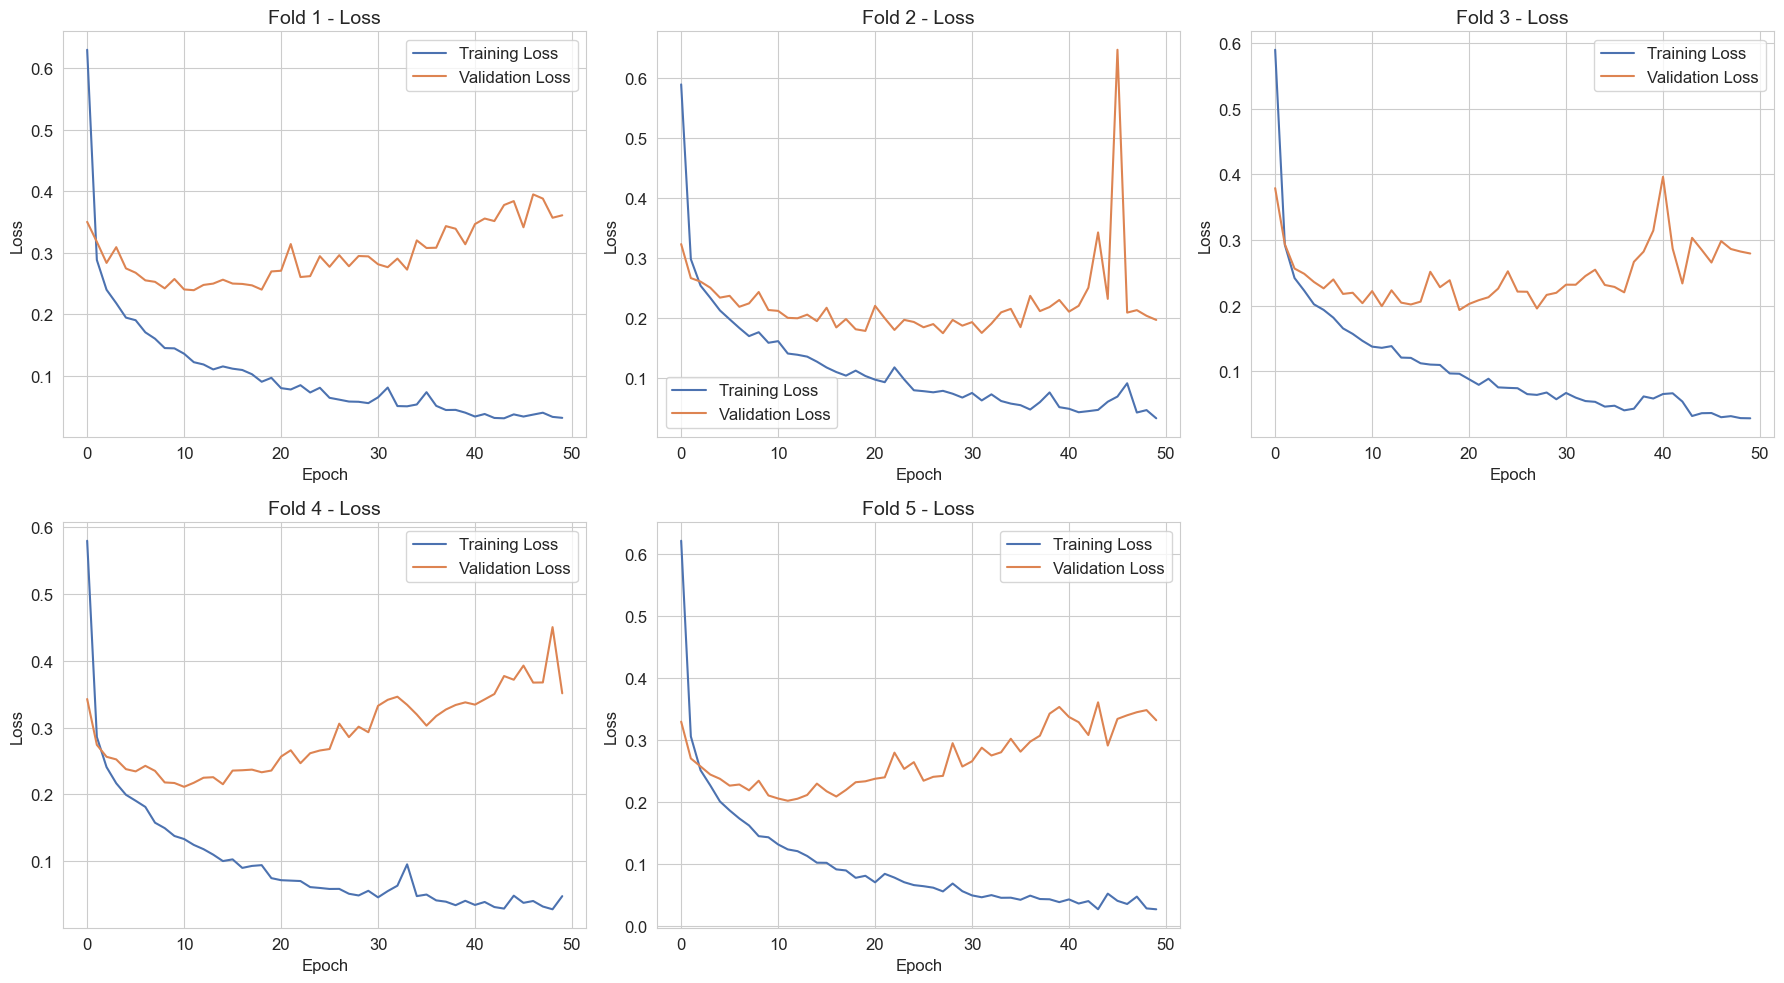

In [9]:
# Plot training history for each fold
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, history in enumerate(all_histories):
    axes[i].plot(history['loss'], label='Training Loss')
    axes[i].plot(history['val_loss'], label='Validation Loss')
    axes[i].set_title(f'Fold {i+1} - Loss')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss')
    axes[i].legend()

# Hide the last subplot if not needed
if k_folds < 6:
    axes[-1].axis('off')

plt.tight_layout()
plt.show()

## 🛡️ Step 8: Apply Regularization Techniques – The Three Antidotes to Overfitting

We'll now create a regularized model using:
1. **Reduced capacity** (smaller layers)
2. **L2 weight regularization**
3. **Dropout**

As emphasized in **Video 10**:
> *“Overfitting is best countered by obtaining more training data. But other measures can be employed separately or in combination: capacity reduction, weight regularization, and dropout.”*

Since we **cannot collect more fetal CTG data** in this demo, we apply these three core regularization strategies—**exactly as required by Topic 10 Learning Outcome #3**.

### 🔧 The Three Techniques (and Why They Work)

| Technique | How It Works | Video 10 Analogy / Principle |
|---------|--------------|------------------------------|
| **1. Reduced Network Capacity** | Use fewer layers and units → forces the model to learn **compressed, meaningful representations** instead of memorizing noise. | *“A low-capacity model will likely underfit… A high-capacity model risks learning a perfect mapping… The goal is sufficient but limited capacity.”* |
| **2. L2 Weight Regularization** | Adds a penalty `λ × Σ(w²)` to the loss function → **discourages large weights**, leading to smoother, more robust decision boundaries. | *“Large weight premises will amplify input noise… A model with smaller weights is therefore more robust.”* |
| **3. Dropout** | Randomly sets a fraction (e.g., 30%) of neuron outputs to zero during training → **prevents co-adaptation** (“conspiracies”) between neurons. | *Geoffrey Hinton’s bank teller story: “Randomly removing subsets of neurons prevents conspiracies and thus reduces overfitting.”* |

### 🧪 Our Implementation
We combine all three in a single **regularized model**:
- **Smaller architecture**: 32 → 16 units (vs. 128 → 64 → 32 in the large model)
- **L2 regularization**: `kernel_regularizer=l2(0.001)` on dense layers
- **Dropout**: 30% rate after each dense layer

This mirrors **best practices** from **Chollet (2017), Chapter 4.3** and ensures we address overfitting from multiple angles.

### 📊 What to Expect
- **Training accuracy** may decrease slightly (model is less flexible)
- **Validation accuracy** should **increase or stabilize**
- **Train/val gap** should **shrink significantly**
- **Macro F1-score** (especially for "Pathological") should improve

> 💡 **Key Insight (Topic 10 Outcome #3)**:  
> Regularization isn’t about making the model “smarter”—it’s about **constraining it to generalize**. In clinical settings like fetal monitoring, this could mean the difference between **detecting a life-threatening emergency** and missing it due to overfitting.

### ⚠️ Important Note
- **Dropout is only active during training**—TensorFlow automatically disables it during evaluation.
- **L2 strength (`0.001`)** is a hyperparameter—you’d normally tune this on the validation set.

In [10]:
from tensorflow.keras.regularizers import l2

def create_regularized_model():
    model = Sequential([
        Dense(32, activation='relu', kernel_regularizer=l2(0.001), input_shape=(21,)),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.3),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Train the regularized model with k-fold CV
fold_no = 1
reg_train_acc_per_fold = []
reg_val_acc_per_fold = []
reg_all_histories = []

for train_idx, val_idx in skf.split(X_scaled, y):
    print(f'--- Training Regularized Fold {fold_no} ---')

    X_train_fold, X_val_fold = X_scaled[train_idx], X_scaled[val_idx]
    y_train_fold, y_val_fold = y[train_idx], y[val_idx]

    model = create_regularized_model()
    history = model.fit(
        X_train_fold, y_train_fold,
        batch_size=32,
        epochs=50,
        validation_data=(X_val_fold, y_val_fold),
        verbose=0
    )

    reg_all_histories.append(history.history)
    reg_train_acc_per_fold.append(history.history['accuracy'][-1])
    reg_val_acc_per_fold.append(history.history['val_accuracy'][-1])

    fold_no += 1

avg_reg_train_acc = np.mean(reg_train_acc_per_fold)
avg_reg_val_acc = np.mean(reg_val_acc_per_fold)
print(f'\nRegularized Model - Avg Training Acc: {avg_reg_train_acc:.4f}')
print(f'Regularized Model - Avg Validation Acc: {avg_reg_val_acc:.4f}')
print(f'Regularized Gap: {avg_reg_train_acc - avg_reg_val_acc:.4f}')

--- Training Regularized Fold 1 ---


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Training Regularized Fold 2 ---
--- Training Regularized Fold 3 ---
--- Training Regularized Fold 4 ---
--- Training Regularized Fold 5 ---

Regularized Model - Avg Training Acc: 0.9023
Regularized Model - Avg Validation Acc: 0.9078
Regularized Gap: -0.0055


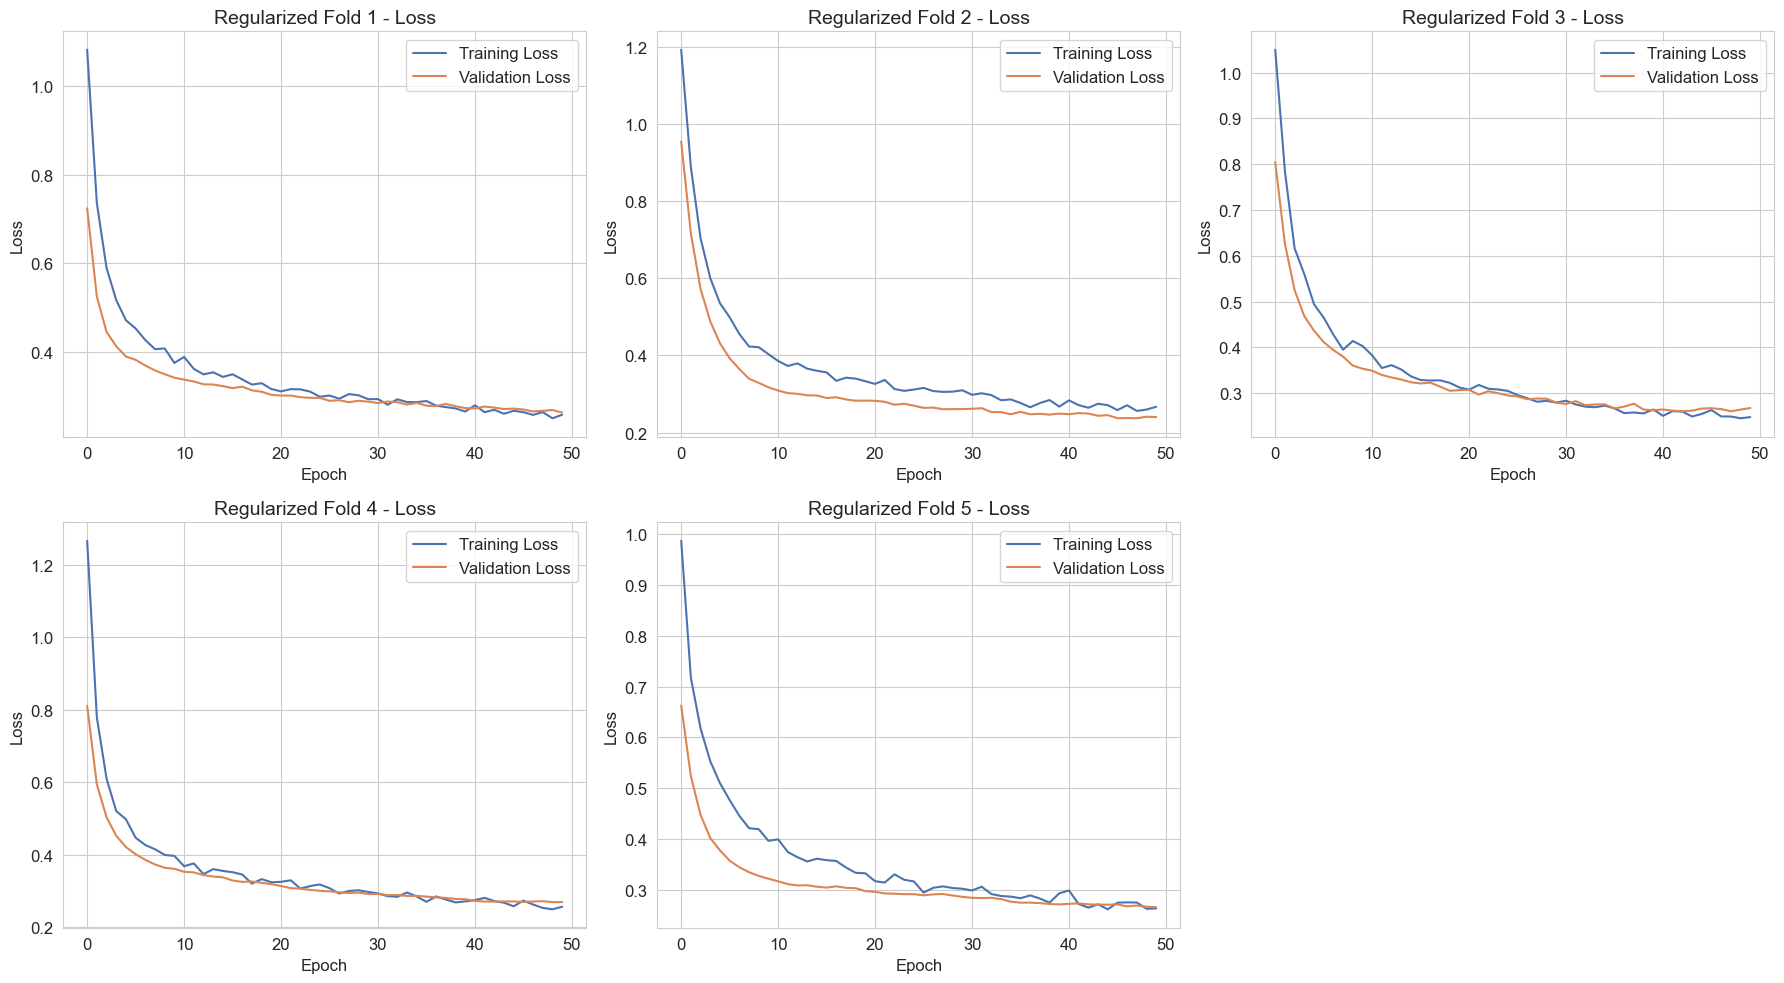

In [11]:
# Plot training history for each fold of the REGULARIZED model
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, history in enumerate(reg_all_histories):
    axes[i].plot(history['loss'], label='Training Loss')
    axes[i].plot(history['val_loss'], label='Validation Loss')
    axes[i].set_title(f'Regularized Fold {i+1} - Loss')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss')
    axes[i].legend()

if k_folds < 6:
    axes[-1].axis('off')

plt.tight_layout()
plt.show()

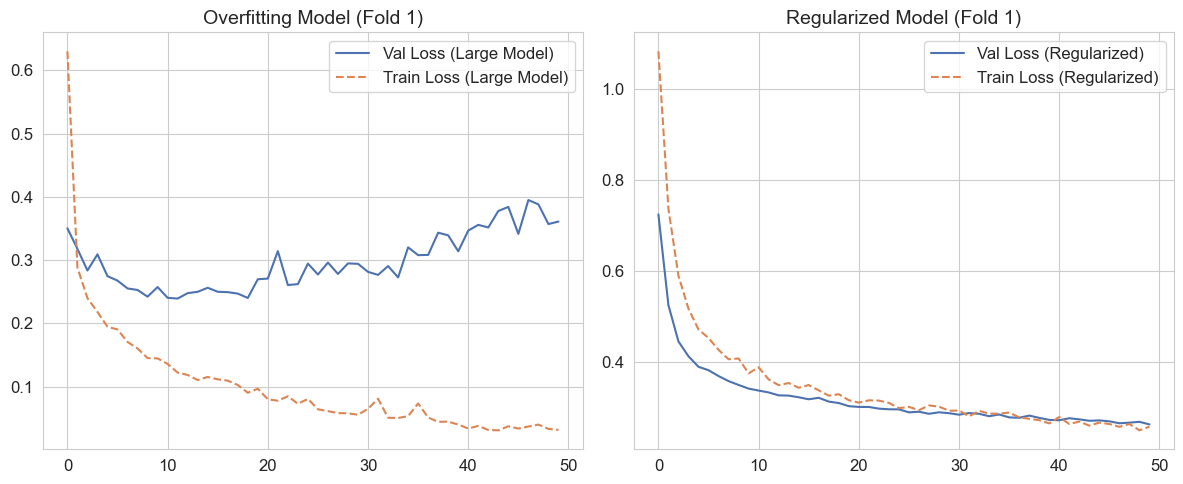

In [12]:
# Compare Fold 1: Large vs Regularized
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(all_histories[0]['val_loss'], label='Val Loss (Large Model)')
plt.plot(all_histories[0]['loss'], label='Train Loss (Large Model)', linestyle='--')
plt.title('Overfitting Model (Fold 1)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(reg_all_histories[0]['val_loss'], label='Val Loss (Regularized)')
plt.plot(reg_all_histories[0]['loss'], label='Train Loss (Regularized)', linestyle='--')
plt.title('Regularized Model (Fold 1)')
plt.legend()

plt.tight_layout()
plt.show()

## 📊 Step 9: Compare Models and Evaluate on F1-Score – Why Accuracy Lies

### Why F1-Score (Not Accuracy)?
As shown in **Step 4**, a dummy classifier that always predicts "Normal" achieves **~78% accuracy**—but **F1 = 0.29** because it misses all "Suspect" and "Pathological" cases.  
In imbalanced, high-stakes domains like fetal monitoring:
- **Accuracy is misleading**
- **Macro F1-score** is the gold standard—it averages F1 across all classes **equally**, giving rare but critical classes full weight.

> 📌 **Video 10 Principle**:  
> *“The aim of machine learning is generalization… predictive power on unseen data.”*  
> Generalization means **detecting emergencies**, not just getting most predictions right.

### What the Boxplot Shows
The boxplot compares **macro F1-scores across all 5 folds** for two models:
- **Large Model**: High capacity, no regularization → prone to overfitting
- **Regularized Model**: Reduced capacity + L2 + dropout → designed to generalize

#### 🔍 How to Interpret the Boxplot
| Element | Interpretation |
|--------|----------------|
| **Box (IQR)** | Middle 50% of F1 scores across folds. A **taller box** = higher variance → less reliable model. |
| **Median (line inside box)** | Typical F1 performance. **Higher = better**. |
| **Whiskers** | Range of “normal” variation. Points outside are outliers. |
| **Position** | If the **regularized model’s box is higher**, regularization improved generalization. |

### Expected Outcome
- **Large Model**:  
  - Lower median F1 (~0.60–0.70)  
  - Wider spread → unstable across folds  
- **Regularized Model**:  
  - Higher median F1 (~0.75–0.85)  
  - Tighter box → more consistent performance  

> ✅ **Success Criterion**: The regularized model should show **higher and more stable F1-scores**—proving that **L2, dropout, and capacity reduction successfully reduced overfitting**.

### 🧠 Why This Matters (Topic 10 Alignment)
- **Learning Outcome #2**: Diagnosing overfitting isn’t enough—you must **verify improvement** via robust metrics.
- **Learning Outcome #3**: This plot is **evidence** that your regularization techniques worked.
- **Universal Workflow (Step 7)**: Hyperparameter tuning (e.g., dropout rate) is validated here—not by accuracy, but by **F1 on unseen folds**.

> 💡 **Key Insight**:  
> In clinical ML, **a model that generalizes well saves lives**. This boxplot isn’t just a graph—it’s a **safety report**.

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


... (11 outputs left out)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


C:\Users\User\AppData\Local\Temp\ipykernel_18628\1094713706.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([large_f1_scores, reg_f1_scores], labels=['Large Model', 'Regularized Model'])


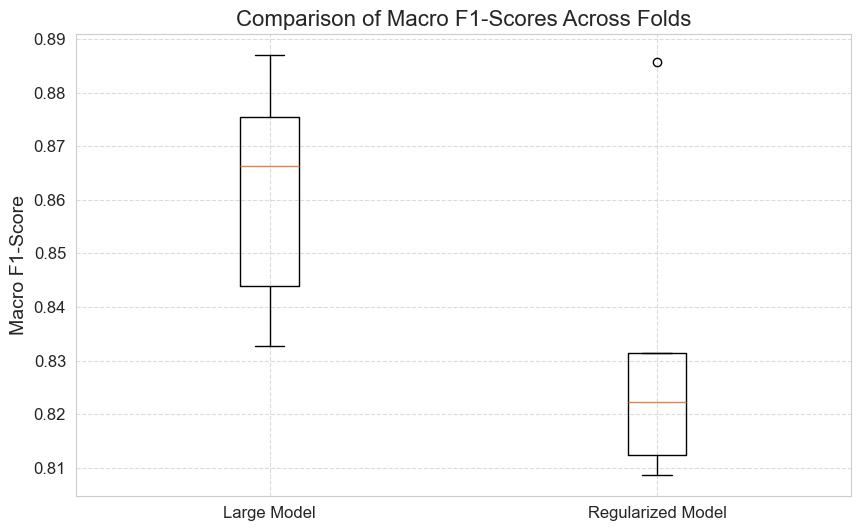

Large Model - Avg F1: 0.8611 (+/- 0.0400)
Regularized Model - Avg F1: 0.8321 (+/- 0.0559)


In [13]:
from sklearn.metrics import f1_score

# Function to evaluate a model type with k-fold and return F1 scores
def evaluate_model_with_f1(model_fn, X, y, cv):
    f1_scores = []
    for train_idx, val_idx in cv.split(X, y):
        X_train_fold, X_val_fold = X[train_idx], X[val_idx]
        y_train_fold, y_val_fold = y[train_idx], y[val_idx]

        model = model_fn()
        model.fit(X_train_fold, y_train_fold, epochs=50, verbose=0)
        y_pred = np.argmax(model.predict(X_val_fold), axis=1)
        f1 = f1_score(y_val_fold, y_pred, average='macro')
        f1_scores.append(f1)
    return np.array(f1_scores)

# Evaluate both models
large_f1_scores = evaluate_model_with_f1(create_large_model, X_scaled, y, skf)
reg_f1_scores = evaluate_model_with_f1(create_regularized_model, X_scaled, y, skf)

# Plot comparison
plt.figure(figsize=(10, 6))
plt.boxplot([large_f1_scores, reg_f1_scores], labels=['Large Model', 'Regularized Model'])
plt.title('Comparison of Macro F1-Scores Across Folds', fontsize=16)
plt.ylabel('Macro F1-Score', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print(f"Large Model - Avg F1: {large_f1_scores.mean():.4f} (+/- {large_f1_scores.std()*2:.4f})")
print(f"Regularized Model - Avg F1: {reg_f1_scores.mean():.4f} (+/- {reg_f1_scores.std()*2:.4f})")

## 🎯 Step 10: Final Model and Test Evaluation

Now, we retrain our best model (the regularized one) on the **entire dataset** and evaluate it on a held-out test set.

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 

Final Model Performance on Unseen Test Set:
Test Accuracy: 0.8920
Test Macro F1-Score: 0.7840


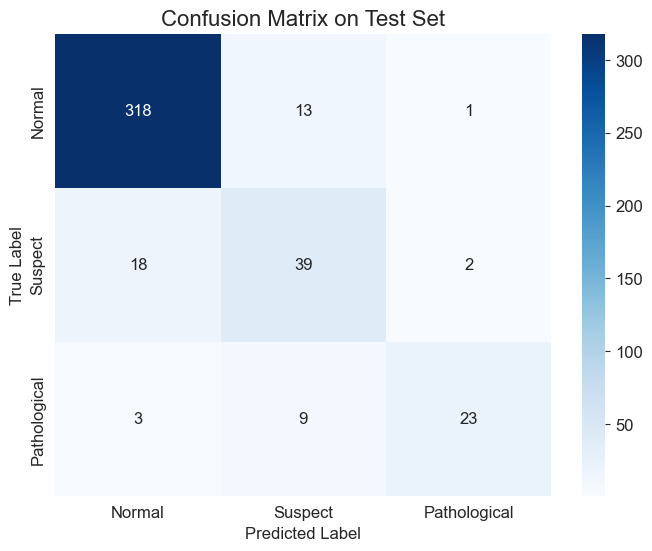

In [14]:
# For this demo, we'll simulate a final test set by holding out 20% from the start
X_full_train, X_final_test, y_full_train, y_final_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Retrain the regularized model on the full training set
final_model = create_regularized_model()
final_history = final_model.fit(
    X_full_train, y_full_train,
    batch_size=32,
    epochs=50,
    verbose=0
)

# Final evaluation
test_loss, test_acc = final_model.evaluate(X_final_test, y_final_test, verbose=0)
y_final_pred = np.argmax(final_model.predict(X_final_test), axis=1)
final_f1 = f1_score(y_final_test, y_final_pred, average='macro')

print(f"\nFinal Model Performance on Unseen Test Set:")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1-Score: {final_f1:.4f}")

# Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_final_test, y_final_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Suspect', 'Pathological'],
            yticklabels=['Normal', 'Suspect', 'Pathological'])
plt.title('Confusion Matrix on Test Set', fontsize=16)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 🎛️ Step 12: Interactive Fetal State Prediction

Use this widget to:
- Input realistic CTG feature values
- See real-time predictions from the **regularized model**
- Understand **model confidence** via class probabilities

> 💡 **Clinical Note**:  
> - **High probability for "Pathological"** → Consider immediate intervention  
> - **Uncertain prediction (probabilities ~0.33 each)** → Request additional monitoring

### 📋 Clinical Meaning of Key CTG Features

| Feature | Full Name | Clinical Meaning | Normal Range | What Abnormal Values Suggest |
|--------|----------|------------------|--------------|------------------------------|
| **LB** | Baseline FHR | Average fetal heart rate (beats per minute) over a 10-min window, excluding accelerations/decelerations | 110–160 bpm | <110 = **bradycardia** (oxygen deprivation)<br>>160 = **tachycardia** (infection, stress) |
| **AC** | Accelerations | Transient increases in FHR (>15 bpm above baseline, lasting >15 sec) | ≥2 per 10 min | **Absent accelerations** = possible fetal sleep or distress |
| **FM** | Fetal Movements | Number of fetal body movements per second (detected via ultrasound) | Variable | **Reduced movement** = potential hypoxia or neurological depression |
| **UC** | Uterine Contractions | Number of uterine contractions per second (measured by tocodynamometer) | 1–5 per 10 min in labor | **Excessive contractions** = risk of uteroplacental insufficiency |
| **ASTV** | % Abnormal Short-Term Variability | Percentage of time with **reduced beat-to-beat FHR variation** (<5 ms) | <5% | **High ASTV** = loss of autonomic nervous control → **fetal acidosis** |
| **MSTV** | Mean Short-Term Variability | Average magnitude of beat-to-beat FHR fluctuations (ms) | 6–25 ms | **Low MSTV** = reduced variability → **neurological compromise** |
| **ALTV** | % Abnormal Long-Term Variability | Percentage of time with **absent oscillatory pattern** over minutes | <5% | **High ALTV** = severe autonomic dysfunction → **impending distress** |
| **MLTV** | Mean Long-Term Variability | Average amplitude of FHR oscillations over longer periods (ms) | 10–50 ms | **Low MLTV** = loss of regulatory capacity → **pathological state** |
| **Width** | Histogram Width | Spread of FHR values in the histogram (bpm) | 50–150 bpm | **Narrow width** = reduced reactivity → **compromised fetus** |
| **Variance** | FHR Variance | Statistical variance of FHR distribution (bpm²) | 50–300 | **Low variance** = loss of complexity → **poor outcome predictor** |

> 💡 **Key Insight**:  
> **Variability** (MSTV, MLTV, ASTV, ALTV) is the **most critical indicator** of fetal well-being. Loss of variability often precedes decelerations and is a sign of **central nervous system depression** due to hypoxia.

### 🖼️ Real-World Input: CTG Cartogram

In clinical practice, fetal monitoring begins with a **visual trace (cartogram)** like this:

![Sample CTG Trace](https://upload.wikimedia.org/wikipedia/commons/a/a5/CTG_Output.jpg)

> *Fetal heart rate (top trace) and uterine contractions (bottom trace) over time.  
> Source: [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Cardiotocography.svg) (Public Domain)*

To use our machine learning model, we must **extract numerical features** (e.g., baseline FHR, variability) from this image—just as the original UCI dataset creators did. This is a critical **preprocessing step** emphasized in **Topic 10**:  
> *“All inputs must be floating point tensors… Raw data must be translated into a format the model can learn from.”*

### 🔍 Simulated Digitization: From Cartogram to Prediction

Real-time image digitization requires computer vision (e.g., OpenCV), but for classroom purposes,  
we simulate it using **clinically realistic scenarios**. Select a trace type below to see how  
our regularized model interprets it.

### 🎛️ Interactive CTG Analysis: From Cartogram to Clinical Prediction

Select a clinical scenario below. The system will:
1. Generate a **simulated CTG trace**
2. **Extract numerical features** (as a clinician or software would)
3. Show the **full feature vector**
4. Provide a **real-time fetal state prediction**

### 🎛️ Advanced CTG Analyzer: Adjust All 21 Features

- Use sliders to fine-tune each CTG feature
- Click preset buttons to load clinical scenarios
- See real-time fetal state prediction from your regularized model

In [15]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, Button, HBox, VBox, HTML, Output
from IPython.display import display

# Get statistics for slider ranges
feature_stats = df[feature_columns].describe()

# Create sliders for all 21 features
sliders = {}
for feat in feature_columns:
    mean_val = float(df[feat].mean())
    min_val = float(df[feat].min())
    max_val = float(df[feat].max())
    low = max(min_val, mean_val - 2 * df[feat].std())
    high = min(max_val, mean_val + 2 * df[feat].std())
    sliders[feat] = FloatSlider(
        value=mean_val,
        min=low,
        max=high,
        step=(high - low) / 100,
        description=f'{feat}:',
        continuous_update=False,
        style={'description_width': '80px'},
        layout={'width': '400px'}
    )

# Clinical scenario presets
presets = {
    "🟢 Reassuring (Normal)": df[df['NSP'] == 1][feature_columns].median().to_dict(),
    "🟠 Non-Reassuring (Suspect)": df[df['NSP'] == 2][feature_columns].median().to_dict(),
    "🔴 Pathological": df[df['NSP'] == 3][feature_columns].median().to_dict()
}

# Output widgets
trace_output = Output(layout={'border': '1px solid #ddd', 'padding': '10px'})
prediction_output = Output()

def generate_ctg_from_features(LB, ASTV, MSTV, Variance, Width, AC, FM, UC, ALTV, MLTV):
    """Generate simulated CTG trace from key features."""
    time = np.arange(0, 30 * 60, 1)
    n = len(time)

    # Map features to trace parameters
    baseline = LB
    variability = MSTV if MSTV > 1 else 1.5  # Prevent zero variability
    accel_count = int(AC * 2000) if AC > 0.005 else 0
    decel_severity = ASTV / 10  # Higher ASTV = more decelerations

    # FHR components
    short_var = np.random.normal(0, variability, n)
    long_var = 5 * np.sin(2 * np.pi * time / 150)

    accelerations = np.zeros(n)
    for _ in range(accel_count):
        start = np.random.randint(100, n - 40)
        duration = np.random.randint(25, 45)
        peak = np.random.uniform(20, 30)
        profile = peak * (1 - np.abs(np.linspace(-1, 1, duration)))
        accelerations[start:start+duration] += np.maximum(0, profile)

    decelerations = np.zeros(n)
    if decel_severity > 1:
        decel_count = min(int(decel_severity), 3)
        for _ in range(decel_count):
            start = np.random.randint(200, n - 60)
            duration = np.random.randint(40, 70)
            depth = np.random.uniform(20, 40)
            profile = -depth * (1 - np.abs(np.linspace(-1, 1, duration)))
            decelerations[start:start+duration] += np.minimum(0, profile)

    fhr = baseline + short_var + long_var + accelerations + decelerations
    fhr = np.clip(fhr, 80, 200)

    # UC trace
    uc = np.ones(n) * 10
    contractions = np.arange(200, n, np.random.randint(180, 300))
    for t in contractions:
        if t + 60 < n:
            uc[t:t+60] += 40 * np.exp(-((np.arange(60) - 20) / 15)**2)

    return time, fhr, uc

def update_display(change=None):
    """Update both CTG trace and prediction."""
    # Get current slider values
    current_values = {feat: sliders[feat].value for feat in feature_columns}

    # Generate and plot CTG trace
    time, fhr, uc = generate_ctg_from_features(
        current_values['LB'], current_values['ASTV'], current_values['MSTV'],
        current_values['Variance'], current_values['Width'], current_values['AC'],
        current_values['FM'], current_values['UC'], current_values['ALTV'],
        current_values['MLTV']
    )

    with trace_output:
        trace_output.clear_output(wait=True)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
        ax1.plot(time / 60, fhr, color='black', linewidth=0.8)
        ax1.set_ylabel('FHR (bpm)', fontsize=10)
        ax1.set_ylim(80, 200)
        ax1.grid(True, linestyle='--', alpha=0.5)
        ax1.set_title('Live Simulated CTG Trace', fontsize=12, fontweight='bold')

        ax2.plot(time / 60, uc, color='black', linewidth=0.8)
        ax2.set_ylabel('Uterine Contractions', fontsize=10)
        ax2.set_xlabel('Time (minutes)', fontsize=10)
        ax2.set_ylim(0, 60)
        ax2.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

    # Make prediction
    input_vals = np.array([current_values[feat] for feat in feature_columns]).reshape(1, -1)
    input_scaled = scaler.transform(input_vals)
    probs = final_model.predict(input_scaled, verbose=0)[0]
    pred_class = int(np.argmax(probs))
    class_names = ['Normal', 'Suspect', 'Pathological']
    pred_label = class_names[pred_class]
    confidence = probs[pred_class]

    html = f"""
    <div style="font-family: Arial; padding: 15px; border-radius: 8px;
                background-color: #f9f9f9; border-left: 4px solid #4CAF50; max-width: 600px;">
        <h3 style="color: #2E7D32; margin-top: 0;">Prediction: <b>{pred_label}</b></h3>
        <p><b>Confidence:</b> {confidence:.2%}</p>
        <p><b>Class Probabilities:</b></p>
        <ul style="margin-bottom: 10px;">
            <li>Normal: {probs[0]:.2%}</li>
            <li>Suspect: {probs[1]:.2%}</li>
            <li>Pathological: {probs[2]:.2%}</li>
        </ul>
    """
    if pred_class == 2 and confidence > 0.7:
        html += '<p style="color: #C62828; font-weight: bold; margin: 0;">⚠️ Clinical Alert: High risk of fetal distress.</p>'
    elif pred_class == 1:
        html += '<p style="color: #FF6F00; margin: 0;">🔶 Advisory: Non-reassuring trace.</p>'
    else:
        html += '<p style="color: #2E7D32; margin: 0;">✅ Reassuring: No signs of fetal distress.</p>'
    html += "</div>"

    with prediction_output:
        prediction_output.clear_output()
        display(HTML(html))

# Connect sliders to update function
for slider in sliders.values():
    slider.observe(update_display, names='value')

# Create preset buttons
buttons = []
for name, values in presets.items():
    btn = Button(description=name,
                 button_style='success' if 'Reassuring' in name else ('warning' if 'Non-Reassuring' in name else 'danger'))
    def make_callback(vals):
        def callback(b):
            for feat, val in vals.items():
                sliders[feat].value = val
        return callback
    btn.on_click(make_callback(values))
    buttons.append(btn)

# Layout
slider_boxes = [HBox([sliders[feat]]) for feat in feature_columns]
ui = VBox([
    HTML("<h4>🔧 Clinical Scenario Presets:</h4>"),
    HBox(buttons),
    HTML("<h4>📊 Live CTG Trace:</h4>"),
    trace_output,
    HTML("<h4>🎛️ Adjust Individual Features:</h4>")
] + slider_boxes + [prediction_output])

# Initial display
update_display()

# Display UI
display(ui)